In [1]:
import pandas as pd
import numpy as np
import joblib
from pathlib import Path

project_path = Path.cwd()

if project_path.name == "notebooks":
    project_path = project_path.parent

models_path = project_path / "models"
data_path = project_path / "data" / "processed"
reports_path = project_path / "docs" / "explainability"

reports_path.mkdir(parents=True, exist_ok=True)

# Ngarkojme SVM qe kemi ruajtur ne Notebook 05
model_svm = joblib.load(
    models_path / "svm_tuned_validation.joblib"
)

# Lexojme vetem Validation
val_df = pd.read_csv(data_path / "validation.csv")

X_val = val_df["text"]
y_val = val_df["label"]

predictions = model_svm.predict(X_val)

print("Model loaded successfully!")
print("Validation samples:", len(val_df))
print("Disease classes:",
      len(model_svm.named_steps["classifier"].classes_))
print("Correct predictions:",
      (predictions == y_val).sum())
print("Incorrect predictions:",
      (predictions != y_val).sum())

Model loaded successfully!
Validation samples: 178
Disease classes: 24
Correct predictions: 177
Incorrect predictions: 1


In [2]:
analysis_df = val_df[["text", "label"]].copy()

analysis_df["prediction"] = predictions

analysis_df["correct"] = (
    analysis_df["label"] == analysis_df["prediction"]
)

# Gjejme shembullin e gabuar
error_samples = analysis_df[
    ~analysis_df["correct"]
]

print("Incorrect predictions:")
display(error_samples)

# Zgjedhim nje shembull te sakte te Migraine
correct_migraine = analysis_df[
    (analysis_df["label"] == "Migraine")
    & (analysis_df["correct"])
]

if len(correct_migraine) == 0:
    raise ValueError("No correct Migraine example found.")

correct_example = correct_migraine.iloc[0]

print("\nCorrect example:")
print("Actual:", correct_example["label"])
print("Predicted:", correct_example["prediction"])
print("Text:", correct_example["text"])

Incorrect predictions:


,text,label,prediction,correct
21,I'm feeling fatigued and have no energy. I can...,Chicken pox,Common Cold,False



Correct example:
Actual: Migraine
Predicted: Migraine
Text: Along with recurrent headaches and blurred vision, I suffer acid reflux and trouble digesting my food.


In [3]:
from lime.lime_text import LimeTextExplainer
from scipy.special import softmax

# Emrat e 24 klasave sipas modelit
class_names = list(
    model_svm.named_steps["classifier"].classes_
)

# Funksioni qe do te perdore LIME
def svm_scores_for_lime(texts):
    scores = model_svm.decision_function(
        list(texts)
    )
    return softmax(scores, axis=1)

# Krijimi i LIME Explainer
explainer = LimeTextExplainer(
    class_names=class_names,
    random_state=42
)

print("LIME Explainer ready!")
print("Total classes:", len(class_names))

LIME Explainer ready!
Total classes: 24


Actual disease: Migraine
Predicted disease: Migraine

Symptom description:
Along with recurrent headaches and blurred vision, I suffer acid reflux and trouble digesting my food.

LIME word contributions:
vision: 0.0625
reflux: 0.0247
headaches: 0.0222
acid: 0.0208
suffer: -0.0204
recurrent: -0.0113
trouble: -0.0093
food: -0.0084
blurred: 0.0056
Along: 0.0038


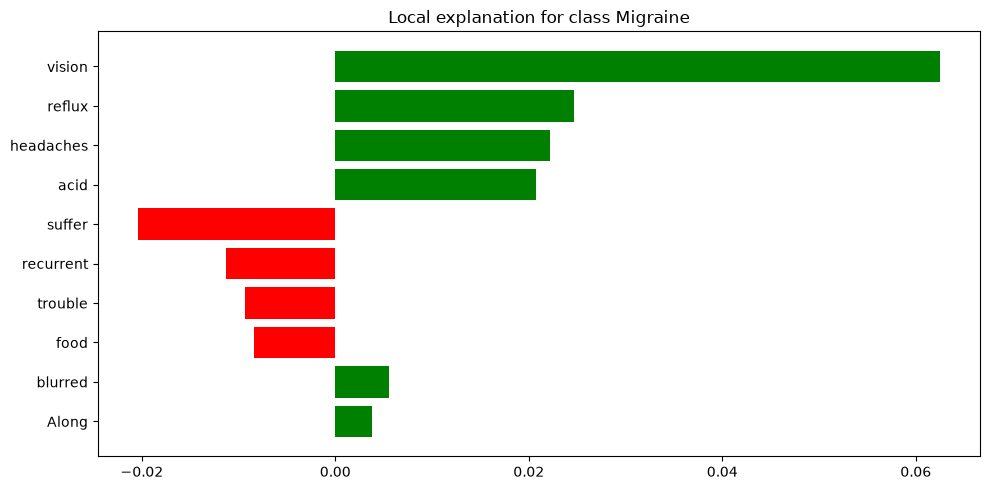

In [4]:
text_example = correct_example["text"]
predicted_disease = correct_example["prediction"]

# Gjejme indeksin e klases se parashikuar
class_index = class_names.index(predicted_disease)

# Gjenerojme shpjegimin
explanation = explainer.explain_instance(
    text_instance=text_example,
    classifier_fn=svm_scores_for_lime,
    labels=(class_index,),
    num_features=10,
    num_samples=1000
)

print("Actual disease:", correct_example["label"])
print("Predicted disease:", predicted_disease)
print("\nSymptom description:")
print(text_example)

print("\nLIME word contributions:")
for word, weight in explanation.as_list(label=class_index):
    print(f"{word}: {weight:.4f}")

# Grafiku
fig = explanation.as_pyplot_figure(label=class_index)

fig.set_size_inches(10, 5)
fig.tight_layout()

fig.savefig(
    reports_path / "lime_correct_prediction.png",
    dpi=200,
    bbox_inches="tight"
)

Actual disease: Chicken pox
Predicted disease: Common Cold

Full text:
I'm feeling fatigued and have no energy. I can barely keep my eyes open during the day, and I've been feeling lethargic and unable to motivate myself.

LIME word contributions:
can: 0.0199
barely: 0.0145
the: -0.0059
ve: 0.0059
have: -0.0057
lethargic: -0.0056
unable: 0.0052
and: 0.0046
my: 0.0045
eyes: 0.0030


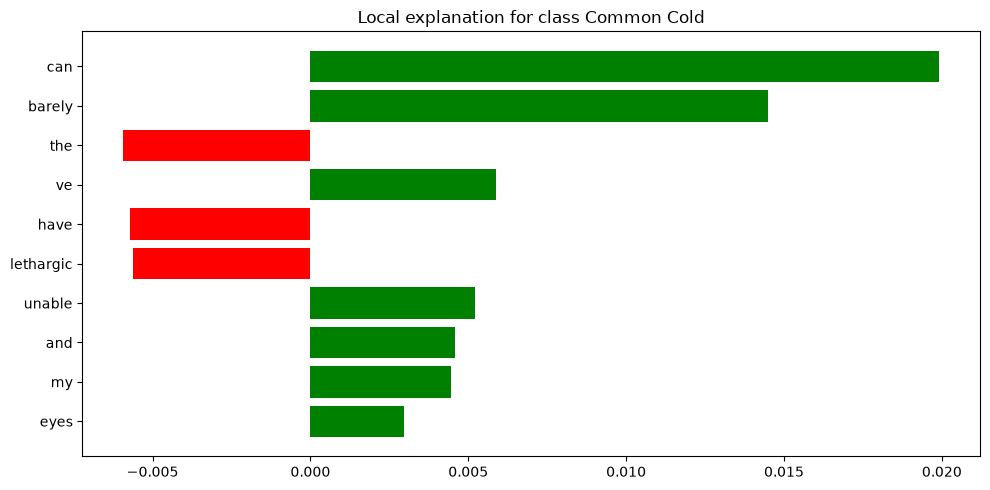

In [5]:
if len(error_samples) == 0:
    raise ValueError("No incorrect predictions found.")

error_example = error_samples.iloc[0]

error_text = error_example["text"]
actual_disease = error_example["label"]
predicted_disease = error_example["prediction"]

error_class_index = class_names.index(
    predicted_disease
)

error_explanation = explainer.explain_instance(
    text_instance=error_text,
    classifier_fn=svm_scores_for_lime,
    labels=(error_class_index,),
    num_features=10,
    num_samples=1000
)

print("Actual disease:", actual_disease)
print("Predicted disease:", predicted_disease)

print("\nFull text:")
print(error_text)

print("\nLIME word contributions:")
for word, weight in error_explanation.as_list(
    label=error_class_index
):
    print(f"{word}: {weight:.4f}")

fig = error_explanation.as_pyplot_figure(
    label=error_class_index
)

fig.set_size_inches(10, 5)
fig.tight_layout()

fig.savefig(
    reports_path / "lime_incorrect_prediction.png",
    dpi=200,
    bbox_inches="tight"
)

In [6]:
report_file = reports_path / "lime_explanations_report.txt"

with open(report_file, "w", encoding="utf-8") as f:
    f.write("MODEL EXPLAINABILITY - LIME\n")
    f.write("=" * 50 + "\n\n")

    f.write("MODEL: Tuned LinearSVC\n")
    f.write("DATA: Validation set\n")
    f.write("LIME input: softmax of SVM decision scores\n")
    f.write("Note: Scores are not calibrated probabilities.\n\n")

    f.write("CORRECT PREDICTION\n")
    f.write("-" * 40 + "\n")
    f.write(f"Actual: {correct_example['label']}\n")
    f.write(f"Predicted: {correct_example['prediction']}\n")
    f.write(f"Text: {text_example}\n\n")

    for word, weight in explanation.as_list(label=class_index):
        f.write(f"{word}: {weight:.4f}\n")

    f.write("\nINCORRECT PREDICTION\n")
    f.write("-" * 40 + "\n")
    f.write(f"Actual: {actual_disease}\n")
    f.write(f"Predicted: {predicted_disease}\n")
    f.write(f"Text: {error_text}\n\n")

    for word, weight in error_explanation.as_list(
        label=error_class_index
    ):
        f.write(f"{word}: {weight:.4f}\n")

print("Report saved successfully!")
print(report_file)

Report saved successfully!
c:\Projects\Bachelor-Thesis\docs\explainability\lime_explanations_report.txt


In [7]:
import pandas as pd
import numpy as np

tfidf = model_svm.named_steps["tfidf"]
classifier = model_svm.named_steps["classifier"]

text = correct_example["text"]
predicted_class = correct_example["prediction"]

class_idx = list(classifier.classes_).index(
    predicted_class
)

# TF-IDF representation e tekstit
X_text = tfidf.transform([text])

# Kontributet e seciles fjale ne decision score
contributions = (
    X_text.toarray()[0] * classifier.coef_[class_idx]
)

feature_names = tfidf.get_feature_names_out()

word_contributions = pd.DataFrame({
    "Word": feature_names,
    "Contribution": contributions
})

word_contributions = word_contributions[
    word_contributions["Contribution"] != 0
]

word_contributions = word_contributions.sort_values(
    "Contribution",
    ascending=False
)

print("Predicted disease:", predicted_class)

display(word_contributions.head(15))

Predicted disease: Migraine


,Word,Contribution
1309,vision,0.446471
968,reflux,0.207638
16,acid,0.177470
564,headaches,0.174426
329,digesting,0.138946
149,blurred,0.100357
48,along,0.060072
963,recurrent,0.049614
1354,with,0.027778
493,food,0.001812


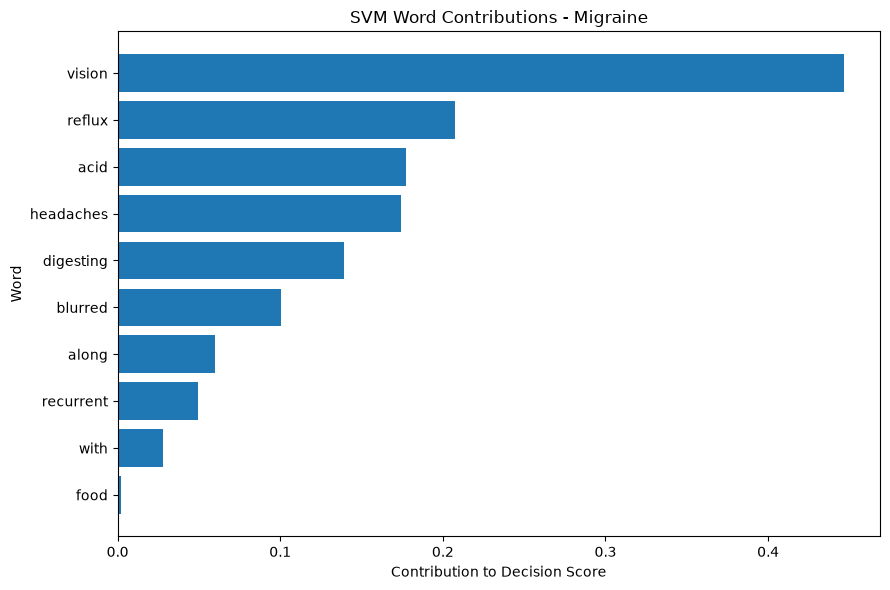

SVM contribution analysis saved successfully!


In [8]:
import matplotlib.pyplot as plt

# Ruajme kontributet e te gjitha fjaleve
word_contributions.to_csv(
    reports_path / "svm_word_contributions.csv",
    index=False
)

# Zgjedhim 10 kontributet me te medha pozitive
top_words = word_contributions.head(10).sort_values(
    "Contribution"
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_words["Word"],
    top_words["Contribution"]
)

plt.title("SVM Word Contributions - Migraine")
plt.xlabel("Contribution to Decision Score")
plt.ylabel("Word")
plt.tight_layout()

plt.savefig(
    reports_path / "svm_word_contributions.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("SVM contribution analysis saved successfully!")